In [1]:

from pathlib import Path
import copy
import random
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import DenseNet121_Weights

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

# Find project root
PROJECT_ROOT = Path.cwd()

while not (
    (PROJECT_ROOT / "data" / "processed").exists()
    and (PROJECT_ROOT / "data" / "raw").exists()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Project root not found. Open this notebook inside "
            "your SOFTWARE-ENGINEERING project."
        )
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_CSV = PROCESSED_DIR / "lesion_split" / "train_metadata.csv"
VAL_CSV = PROCESSED_DIR / "lesion_split" / "val_metadata.csv"
TEST_CSV = PROCESSED_DIR / "lesion_split" / "test_metadata.csv"

IMAGE_DIRS = [
    PROJECT_ROOT / "data" / "raw" / "HAM10000_images_part_1",
    PROJECT_ROOT / "data" / "raw" / "HAM10000_images_part_2",
]

MODEL_DIR = PROJECT_ROOT / "model"
FIGURE_DIR = PROJECT_ROOT / "figures" / "densenet121_training"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

for path in [TRAIN_CSV, VAL_CSV, TEST_CSV, *IMAGE_DIRS]:
    print(("OK      " if path.exists() else "MISSING "), path)

assert all(
    p.exists() for p in [TRAIN_CSV, VAL_CSV, TEST_CSV, *IMAGE_DIRS]
), "One or more paths are missing. Check the printed paths."


Project root: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING
Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU memory: 6.0 GB
OK       C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\data\processed\lesion_split\train_metadata.csv
OK       C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\data\processed\lesion_split\val_metadata.csv
OK       C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\data\processed\lesion_split\test_metadata.csv
OK       C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\data\raw\HAM10000_images_part_1
OK       C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\data\raw\HAM10000_images_part_2


## Separate experiment: dropout fine-tuning from the best lesion-level checkpoint

Run the read-only setup cell immediately below, then run cells 1, 2, and 3 in order. This experiment is self-contained and reads the existing lesion-split CSVs without regenerating them. It does not require running the original split-generation, training, or test-evaluation cells. The test split is opened only in the final evaluation cell.

### 0. Read-only setup for this experiment

This cell locates the project, reads only the existing train/validation splits, and recreates the original lesion-level transforms exactly. It does not write files or read test labels.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import json
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

_dropout_cwd = Path.cwd().resolve()
for _candidate in (_dropout_cwd, *_dropout_cwd.parents):
    if (
        (_candidate / "data" / "processed" / "lesion_split").is_dir()
        and (_candidate / "data" / "raw").is_dir()
        and (_candidate / "model").is_dir()
    ):
        PROJECT_ROOT = _candidate
        break
else:
    raise FileNotFoundError(
        "Could not locate the HAM10000 project from the current working directory."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "model"
DROPOUT_TRAIN_CSV = PROCESSED_DIR / "lesion_split" / "train_metadata.csv"
DROPOUT_VAL_CSV = PROCESSED_DIR / "lesion_split" / "val_metadata.csv"
DROPOUT_TEST_CSV = PROCESSED_DIR / "lesion_split" / "test_metadata.csv"
DROPOUT_IMAGE_DIRS = [
    PROJECT_ROOT / "data" / "raw" / "HAM10000_images_part_1",
    PROJECT_ROOT / "data" / "raw" / "HAM10000_images_part_2",
]
assert all(
    path.is_file() for path in
    [DROPOUT_TRAIN_CSV, DROPOUT_VAL_CSV, DROPOUT_TEST_CSV]
), "One or more existing lesion-split CSVs are missing."
assert all(path.is_dir() for path in DROPOUT_IMAGE_DIRS), (
    "One or more HAM10000 image directories are missing."
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DROPOUT_CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
DROPOUT_CLASS_TO_IDX = {
    class_name: index
    for index, class_name in enumerate(DROPOUT_CLASS_NAMES)
}
with open(MODEL_DIR / "densenet121_class_mapping.json", encoding="utf-8") as mapping_file:
    saved_class_mapping = json.load(mapping_file)
assert saved_class_mapping == DROPOUT_CLASS_TO_IDX, (
    f"Checkpoint class order differs from the saved mapping: {saved_class_mapping}"
)

dropout_train_df = pd.read_csv(DROPOUT_TRAIN_CSV)
dropout_val_df = pd.read_csv(DROPOUT_VAL_CSV)
for split_name, split_df in [
    ("train", dropout_train_df),
    ("validation", dropout_val_df),
]:
    assert {"image_id", "dx"}.issubset(split_df.columns), (
        f"{split_name} split is missing image_id/dx columns"
    )
    assert split_df[["image_id", "dx"]].notna().all().all(), (
        f"{split_name} split contains missing image IDs or labels"
    )
    assert set(split_df["dx"].unique()).issubset(DROPOUT_CLASS_TO_IDX), (
        f"Unexpected label in {split_name} split"
    )

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0
dropout_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])
dropout_eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

dropout_image_lookup = {}
for image_dir in DROPOUT_IMAGE_DIRS:
    for image_path in image_dir.glob("*.jpg"):
        if image_path.stem in dropout_image_lookup:
            raise ValueError(f"Duplicate image ID found: {image_path.stem}")
        dropout_image_lookup[image_path.stem] = image_path
for split_name, split_df in [
    ("train", dropout_train_df),
    ("validation", dropout_val_df),
]:
    missing_ids = [
        str(image_id)
        for image_id in split_df["image_id"]
        if str(image_id) not in dropout_image_lookup
    ]
    if missing_ids:
        raise FileNotFoundError(
            f"Missing {split_name} images, for example: {missing_ids[:5]}"
        )

class DropoutHAM10000Dataset(Dataset):
    def __init__(self, dataframe, image_lookup, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.image_lookup = image_lookup
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_id = str(row["image_id"])
        image_path = self.image_lookup[image_id]
        with Image.open(image_path) as image:
            image = image.convert("RGB")
        return self.transform(image), DROPOUT_CLASS_TO_IDX[row["dx"]]

print("Project root:", PROJECT_ROOT)
print("Existing train split:", DROPOUT_TRAIN_CSV)
print("Existing validation split:", DROPOUT_VAL_CSV)
print("Test split (only read in cell 3):", DROPOUT_TEST_CSV)
print("Device:", DEVICE)
print("Class order:", DROPOUT_CLASS_NAMES)
print("Training transform:", dropout_train_transform)
print("Evaluation transform:", dropout_eval_transform)

Project root: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING
Existing train split: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\data\processed\lesion_split\train_metadata.csv
Existing validation split: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\data\processed\lesion_split\val_metadata.csv
Test split (only read in cell 3): C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\data\processed\lesion_split\test_metadata.csv
Device: cuda
Class order: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Training transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.95, 1.05), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Evaluation transfo

### 1. Load the best lesion checkpoint, then replace the classifier

In [3]:
EXPECTED_TRAIN_CSV = (
    PROJECT_ROOT / "data" / "processed" / "lesion_split" / "train_metadata.csv"
)
EXPECTED_VAL_CSV = (
    PROJECT_ROOT / "data" / "processed" / "lesion_split" / "val_metadata.csv"
)
EXPECTED_TEST_CSV = (
    PROJECT_ROOT / "data" / "processed" / "lesion_split" / "test_metadata.csv"
)
assert DROPOUT_TRAIN_CSV.resolve() == EXPECTED_TRAIN_CSV.resolve()
assert DROPOUT_VAL_CSV.resolve() == EXPECTED_VAL_CSV.resolve()
assert DROPOUT_TEST_CSV.resolve() == EXPECTED_TEST_CSV.resolve()
assert all(path.is_file() for path in [
    DROPOUT_TRAIN_CSV, DROPOUT_VAL_CSV, DROPOUT_TEST_CSV
])

DROPOUT_SOURCE_CHECKPOINT = (
    MODEL_DIR / "densenet121_ham10000_lesion_best.pt"
)
DROPOUT_CHECKPOINT_PATH = (
    MODEL_DIR / "densenet121_ham10000_lesion_dropout.pt"
)
DROPOUT_RESUME_PATH = (
    MODEL_DIR / "densenet121_ham10000_lesion_resume.pt"
)
assert MODEL_DIR.resolve() == (PROJECT_ROOT / "model").resolve()
assert DROPOUT_SOURCE_CHECKPOINT.is_file(), (
    f"Best lesion-level checkpoint not found: {DROPOUT_SOURCE_CHECKPOINT}"
)
assert DROPOUT_CHECKPOINT_PATH != DROPOUT_SOURCE_CHECKPOINT
assert DROPOUT_CHECKPOINT_PATH != DROPOUT_RESUME_PATH

# Keep this experiment's datasets and loaders separate from the original pipeline.
dropout_train_dataset = DropoutHAM10000Dataset(
    dropout_train_df, dropout_image_lookup, dropout_train_transform
)
dropout_val_dataset = DropoutHAM10000Dataset(
    dropout_val_df, dropout_image_lookup, dropout_eval_transform
)
dropout_train_loader = DataLoader(
    dropout_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
dropout_val_loader = DataLoader(
    dropout_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

dropout_model = models.densenet121(weights=None)

# First create the same 7-class classifier as the saved checkpoint
dropout_model.classifier = nn.Linear(1024, 7)

source_checkpoint = torch.load(
    DROPOUT_SOURCE_CHECKPOINT,
    map_location=DEVICE,
    weights_only=True
)

dropout_model.load_state_dict(source_checkpoint, strict=True)

# Now replace the classifier with dropout
dropout_model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(1024, 7)
)

dropout_model = dropout_model.to(DEVICE)

print("Original lesion checkpoint loaded successfully.")
print("New classifier:", dropout_model.classifier)

print("Source checkpoint:", DROPOUT_SOURCE_CHECKPOINT)
print("Separate output checkpoint:", DROPOUT_CHECKPOINT_PATH)
print("Device:", DEVICE)
print("Class order:", DROPOUT_CLASS_NAMES)
print("Training transform:", dropout_train_transform)
print("Validation transform:", dropout_eval_transform)

Original lesion checkpoint loaded successfully.
New classifier: Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1024, out_features=7, bias=True)
)
Source checkpoint: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\model\densenet121_ham10000_lesion_best.pt
Separate output checkpoint: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\model\densenet121_ham10000_lesion_dropout.pt
Device: cuda
Class order: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Training transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.95, 1.05), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Validation transform: Compose(
    Resize(size=(224, 224), 

### 2. Fine-tune for five epochs and save the best validation checkpoint

This cell uses only lesion-level train/validation data. Best checkpoint selection is by validation Macro F1, with validation loss as a tie-breaker. It writes only `densenet121_ham10000_lesion_dropout.pt` and does not update the existing history or evaluation artifacts.

In [4]:
DROPOUT_EPOCHS = 5
DROPOUT_LEARNING_RATE = 1e-5
DROPOUT_WEIGHT_DECAY = 1e-4

dropout_train_labels = dropout_train_df["dx"].map(
    DROPOUT_CLASS_TO_IDX
).to_numpy()
dropout_class_indices = np.arange(len(DROPOUT_CLASS_NAMES))
dropout_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=dropout_class_indices,
    y=dropout_train_labels,
)
dropout_class_weights = torch.tensor(
    dropout_class_weights,
    dtype=torch.float32,
    device=DEVICE,
)
dropout_criterion = nn.CrossEntropyLoss(weight=dropout_class_weights)
dropout_optimizer = torch.optim.AdamW(
    dropout_model.parameters(),
    lr=DROPOUT_LEARNING_RATE,
    weight_decay=DROPOUT_WEIGHT_DECAY,
)

best_dropout_macro_f1 = float("-inf")
best_dropout_val_loss = float("inf")
best_dropout_epoch = 0
dropout_history = []
DROPOUT_CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)

for epoch in range(1, DROPOUT_EPOCHS + 1):
    dropout_model.train()
    train_loss_sum = 0.0
    train_sample_count = 0

    for images, labels in dropout_train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        dropout_optimizer.zero_grad(set_to_none=True)
        logits = dropout_model(images)
        loss = dropout_criterion(logits, labels)
        loss.backward()
        dropout_optimizer.step()
        train_loss_sum += loss.item() * images.size(0)
        train_sample_count += images.size(0)

    dropout_model.eval()
    val_loss_sum = 0.0
    val_sample_count = 0
    val_predictions = []
    val_targets = []
    with torch.no_grad():
        for images, labels in dropout_val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = dropout_model(images)
            loss = dropout_criterion(logits, labels)
            val_loss_sum += loss.item() * images.size(0)
            val_sample_count += images.size(0)
            val_predictions.extend(logits.argmax(dim=1).cpu().tolist())
            val_targets.extend(labels.cpu().tolist())

    epoch_train_loss = train_loss_sum / train_sample_count
    epoch_val_loss = val_loss_sum / val_sample_count
    epoch_val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        labels=dropout_class_indices,
        average="macro",
        zero_division=0,
    )
    dropout_history.append({
        "epoch": epoch,
        "train_loss": epoch_train_loss,
        "val_loss": epoch_val_loss,
        "val_macro_f1": epoch_val_macro_f1,
    })
    print(
        f"Epoch [{epoch}/{DROPOUT_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Macro F1: {epoch_val_macro_f1:.4f}"
    )

    is_best_dropout = (
        epoch_val_macro_f1 > best_dropout_macro_f1
        or (
            np.isclose(epoch_val_macro_f1, best_dropout_macro_f1)
            and epoch_val_loss < best_dropout_val_loss
        )
    )
    if is_best_dropout:
        best_dropout_macro_f1 = epoch_val_macro_f1
        best_dropout_val_loss = epoch_val_loss
        best_dropout_epoch = epoch
        dropout_checkpoint = {
            "architecture": "DenseNet121",
            "model_state_dict": {
                name: tensor.detach().cpu().clone()
                for name, tensor in dropout_model.state_dict().items()
            },
            "class_names": DROPOUT_CLASS_NAMES,
            "dropout_probability": 0.3,
            "source_checkpoint": str(DROPOUT_SOURCE_CHECKPOINT),
            "best_epoch": best_dropout_epoch,
            "val_loss": best_dropout_val_loss,
            "val_macro_f1": best_dropout_macro_f1,
        }
        # Save only to the new experiment-specific checkpoint path.
        torch.save(dropout_checkpoint, DROPOUT_CHECKPOINT_PATH)

assert DROPOUT_CHECKPOINT_PATH.is_file(), (
    "No best dropout checkpoint was saved."
)
print("Best epoch:", best_dropout_epoch)
print("Best validation Macro F1:", f"{best_dropout_macro_f1:.4f}")
print("Best validation loss:", f"{best_dropout_val_loss:.4f}")
print("Saved separate checkpoint:", DROPOUT_CHECKPOINT_PATH)

Epoch [1/5] Train Loss: 1.3258 | Val Loss: 1.1054 | Val Macro F1: 0.5863
Epoch [2/5] Train Loss: 0.5941 | Val Loss: 0.7790 | Val Macro F1: 0.6560
Epoch [3/5] Train Loss: 0.3971 | Val Loss: 0.6157 | Val Macro F1: 0.7146
Epoch [4/5] Train Loss: 0.3150 | Val Loss: 0.5783 | Val Macro F1: 0.7044
Epoch [5/5] Train Loss: 0.2599 | Val Loss: 0.5370 | Val Macro F1: 0.7233
Best epoch: 5
Best validation Macro F1: 0.7233
Best validation loss: 0.5370
Saved separate checkpoint: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\model\densenet121_ham10000_lesion_dropout.pt


### 3. Final test evaluation of the saved dropout checkpoint

Run only after fine-tuning has saved the new checkpoint. This cell evaluates the untouched lesion-level test CSV and prints accuracy, Macro F1, and per-class precision/recall/F1. It does not write or overwrite any evaluation artifacts.

In [10]:
# 1. Verify checkpoint and test split
assert DROPOUT_CHECKPOINT_PATH.is_file(), (
    f"Dropout checkpoint not found: {DROPOUT_CHECKPOINT_PATH}"
)

assert DROPOUT_TEST_CSV.resolve() == EXPECTED_TEST_CSV.resolve()

# 2. Load test dataset
dropout_test_df = pd.read_csv(DROPOUT_TEST_CSV)

assert {"image_id", "dx"}.issubset(dropout_test_df.columns)
assert set(dropout_test_df["dx"].unique()).issubset(
    DROPOUT_CLASS_TO_IDX
)

dropout_test_dataset = DropoutHAM10000Dataset(
    dropout_test_df,
    dropout_image_lookup,
    dropout_eval_transform
)

dropout_test_loader = DataLoader(
    dropout_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

# 3. Load saved best dropout checkpoint
saved_dropout_checkpoint = torch.load(
    DROPOUT_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True,
)

assert saved_dropout_checkpoint["class_names"] == DROPOUT_CLASS_NAMES
assert saved_dropout_checkpoint["architecture"] == "DenseNet121"

# 4. Reconstruct model architecture
dropout_test_model = models.densenet121(weights=None)

dropout_test_model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(1024, 7),
)

dropout_test_model.load_state_dict(
    saved_dropout_checkpoint["model_state_dict"],
    strict=True,
)

dropout_test_model = dropout_test_model.to(DEVICE)
dropout_test_model.eval()

# 5. Generate test predictions
dropout_test_predictions = []
dropout_test_targets = []

with torch.no_grad():
    for images, labels in dropout_test_loader:
        images = images.to(DEVICE, non_blocking=True)

        logits = dropout_test_model(images)

        dropout_test_predictions.extend(
            logits.argmax(dim=1).cpu().tolist()
        )

        dropout_test_targets.extend(
            labels.cpu().tolist()
        )

# 6. Calculate test accuracy
dropout_test_accuracy = accuracy_score(
    dropout_test_targets,
    dropout_test_predictions,
)

# 7. Calculate test Macro F1
dropout_test_macro_f1 = f1_score(
    dropout_test_targets,
    dropout_test_predictions,
    labels=np.arange(len(DROPOUT_CLASS_NAMES)),
    average="macro",
    zero_division=0,
)

# 8. Calculate per-class metrics
from sklearn.metrics import precision_recall_fscore_support

class_precision, class_recall, class_f1, class_support = (
    precision_recall_fscore_support(
        dropout_test_targets,
        dropout_test_predictions,
        labels=np.arange(len(DROPOUT_CLASS_NAMES)),
        zero_division=0,
    )
)

dropout_per_class_report = pd.DataFrame(
    {
        "precision": class_precision,
        "recall": class_recall,
        "f1-score": class_f1,
        "support": class_support,
    },
    index=DROPOUT_CLASS_NAMES,
)

# 9. Display final results
print("Dropout checkpoint:", DROPOUT_CHECKPOINT_PATH)

print(f"Test accuracy: {dropout_test_accuracy:.4f}")
print(f"Test Macro F1: {dropout_test_macro_f1:.4f}")

print("\nPer-class precision, recall and F1:")
print(dropout_per_class_report.round(4).to_string())

Dropout checkpoint: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\model\densenet121_ham10000_lesion_dropout.pt
Test accuracy: 0.8113
Test Macro F1: 0.6557

Per-class precision, recall and F1:
       precision  recall  f1-score  support
akiec     0.5176  0.6471    0.5752       68
bcc       0.6290  0.7800    0.6964      100
bkl       0.6697  0.7220    0.6948      205
df        0.5000  0.3182    0.3889       22
mel       0.5455  0.6486    0.5926      222
nv        0.9447  0.8650    0.9031     1363
vasc      0.5862  1.0000    0.7391       34


In [2]:
import pandas as pd
from pathlib import Path

# Load the original HAM10000 metadata
metadata_path = Path("../data/raw/HAM10000_metadata.csv")

metadata = pd.read_csv(metadata_path)

print("Metadata shape:", metadata.shape)
print("Available columns:", metadata.columns.tolist())

if "lesion_id" in metadata.columns and "image_id" in metadata.columns:
    print("\nLesion-level splitting is possible.")
    print("Unique images:", metadata["image_id"].nunique())
    print("Unique lesions:", metadata["lesion_id"].nunique())
    print("Missing lesion IDs:", metadata["lesion_id"].isna().sum())
else:
    print("\nRequired columns are missing. Check metadata_path.")

Metadata shape: (10015, 7)
Available columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Lesion-level splitting is possible.
Unique images: 10015
Unique lesions: 7470
Missing lesion IDs: 0


In [3]:
# Check how many images belong to each lesion
images_per_lesion = metadata.groupby("lesion_id")["image_id"].count()

print("Total unique lesions:", metadata["lesion_id"].nunique())
print("Lesions with multiple images:", (images_per_lesion > 1).sum())
print("Maximum images for one lesion:", images_per_lesion.max())

print("\nImages per diagnosis:")
print(metadata["dx"].value_counts())

print("\nUnique lesions per diagnosis:")
print(metadata.groupby("dx")["lesion_id"].nunique())

Total unique lesions: 7470
Lesions with multiple images: 1956
Maximum images for one lesion: 6

Images per diagnosis:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Unique lesions per diagnosis:
dx
akiec     228
bcc       327
bkl       727
df         73
mel       614
nv       5403
vasc       98
Name: lesion_id, dtype: int64


In [5]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

# Output folder: separate from existing split CSVs
output_dir = Path("../data/processed/lesion_split")
output_dir.mkdir(parents=True, exist_ok=True)

# Use original metadata and keep only required columns
df = metadata[["image_id", "lesion_id", "dx"]].copy()

# 3-fold grouped stratified split:
# one fold for test, remaining folds for train/validation
outer_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

trainval_idx, test_idx = next(
    outer_splitter.split(df, y=df["dx"], groups=df["lesion_id"])
)

trainval_df = df.iloc[trainval_idx].copy()
test_df = df.iloc[test_idx].copy()

# Split remaining data into train and validation
inner_splitter = StratifiedGroupKFold(
    n_splits=4, shuffle=True, random_state=43
)

train_idx, val_idx = next(
    inner_splitter.split(
        trainval_df,
        y=trainval_df["dx"],
        groups=trainval_df["lesion_id"]
    )
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

# Save to NEW files; existing CSVs remain unchanged
train_df.to_csv(output_dir / "train_metadata.csv", index=False)
val_df.to_csv(output_dir / "val_metadata.csv", index=False)
test_df.to_csv(output_dir / "test_metadata.csv", index=False)

print("Saved new split files to:", output_dir.resolve())
print("Images - train:", len(train_df),
      "| validation:", len(val_df),
      "| test:", len(test_df))

print("\nUnique lesions - train:", train_df["lesion_id"].nunique(),
      "| validation:", val_df["lesion_id"].nunique(),
      "| test:", test_df["lesion_id"].nunique())

Saved new split files to: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\data\processed\lesion_split
Images - train: 6007 | validation: 1994 | test: 2014

Unique lesions - train: 4482 | validation: 1493 | test: 1495


In [6]:
from pathlib import Path
import pandas as pd

split_dir = Path("../data/processed/lesion_split")

train_new = pd.read_csv(split_dir / "train_metadata.csv")
val_new = pd.read_csv(split_dir / "val_metadata.csv")
test_new = pd.read_csv(split_dir / "test_metadata.csv")

splits = {
    "train": train_new,
    "validation": val_new,
    "test": test_new
}

# Check lesion overlap
print("LESION ID OVERLAP")
for a, b in [("train", "validation"),
             ("train", "test"),
             ("validation", "test")]:
    overlap = (
        set(splits[a]["lesion_id"]) &
        set(splits[b]["lesion_id"])
    )
    print(f"{a} vs {b}: {len(overlap)}")

# Check class distribution
print("\nCLASS DISTRIBUTION")
for name, df in splits.items():
    print(f"\n{name.upper()} — {len(df)} images")
    print(df["dx"].value_counts().sort_index())

# Check all images are accounted for
all_ids = (
    set(train_new["image_id"]) |
    set(val_new["image_id"]) |
    set(test_new["image_id"])
)
print("\nTotal unique image IDs:", len(all_ids))
print("Duplicate image IDs across splits:",
      len(train_new["image_id"]) + len(val_new["image_id"])
      + len(test_new["image_id"]) - len(all_ids))

LESION ID OVERLAP
train vs validation: 0
train vs test: 0
validation vs test: 0

CLASS DISTRIBUTION

TRAIN — 6007 images
dx
akiec     197
bcc       308
bkl       687
df         68
mel       679
nv       3983
vasc       85
Name: count, dtype: int64

VALIDATION — 1994 images
dx
akiec      62
bcc       106
bkl       207
df         25
mel       212
nv       1359
vasc       23
Name: count, dtype: int64

TEST — 2014 images
dx
akiec      68
bcc       100
bkl       205
df         22
mel       222
nv       1363
vasc       34
Name: count, dtype: int64

Total unique image IDs: 10015
Duplicate image IDs across splits: 0


In [7]:


TRAIN_CSV = PROCESSED_DIR / "lesion_split" / "train_metadata.csv"
VAL_CSV = PROCESSED_DIR / "lesion_split" / "val_metadata.csv"
TEST_CSV = PROCESSED_DIR / "lesion_split" / "test_metadata.csv"


CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

for split_name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    missing_columns = {"image_id", "dx"} - set(df.columns)
    if missing_columns:
        raise ValueError(
            f"{split_name} CSV is missing columns: {missing_columns}"
        )

    unknown = set(df["dx"].dropna().unique()) - set(CLASS_NAMES)
    if unknown:
        raise ValueError(f"Unexpected labels in {split_name}: {unknown}")

    if df[["image_id", "dx"]].isna().any().any():
        raise ValueError(f"Missing image IDs or labels in {split_name}")

print("Train rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

print("\nTraining class distribution:")
print(
    train_df["dx"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

# Build image lookup
IMAGE_LOOKUP = {}

for image_dir in IMAGE_DIRS:
    for image_path in image_dir.glob("*.jpg"):
        IMAGE_LOOKUP[image_path.stem] = image_path

print("\nImages found:", len(IMAGE_LOOKUP))

for split_name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    missing = [
        image_id for image_id in df["image_id"].astype(str)
        if image_id not in IMAGE_LOOKUP
    ]
    print(f"{split_name}: missing images = {len(missing)}")

    if missing:
        raise FileNotFoundError(
            f"Example missing image IDs: {missing[:5]}"
        )

# Save the class mapping for future inference/XAI
with open(MODEL_DIR / "densenet121_class_mapping.json", "w") as f:
    json.dump(CLASS_TO_IDX, f, indent=4)


Train rows: 6007
Validation rows: 1994
Test rows: 2014

Training class distribution:
dx
akiec     197
bcc       308
bkl       687
df         68
mel       679
nv       3983
vasc       85
Name: count, dtype: int64

Images found: 10015
train: missing images = 0
validation: missing images = 0
test: missing images = 0


In [8]:

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0  # Reliable on Windows/Jupyter

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, image_lookup, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.image_lookup = image_lookup
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_id = str(row["image_id"])
        image_path = self.image_lookup[image_id]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        image = self.transform(image)
        label = CLASS_TO_IDX[row["dx"]]

        return image, label


train_dataset = HAM10000Dataset(
    train_df, IMAGE_LOOKUP, train_transform
)
val_dataset = HAM10000Dataset(
    val_df, IMAGE_LOOKUP, eval_transform
)
test_dataset = HAM10000Dataset(
    test_df, IMAGE_LOOKUP, eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Number of classes:", len(CLASS_NAMES))


Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Number of classes: 7


In [9]:

from pathlib import Path
import torch

weights_path = (
    Path(torch.hub.get_dir())
    / "checkpoints"
    / "densenet121-a639ec97.pth"
)

print("Expected weights path:", weights_path)
print("Weights already downloaded:", weights_path.exists())

if weights_path.exists():
    print("File size (MB):", round(weights_path.stat().st_size / (1024**2), 2))


Expected weights path: C:\Users\vansh\.cache\torch\hub\checkpoints\densenet121-a639ec97.pth
Weights already downloaded: True
File size (MB): 30.84


In [10]:

# Load pretrained DenseNet121
weights = DenseNet121_Weights.DEFAULT
model = models.densenet121(weights=weights)

# Replace the classifier for 7 HAM10000 classes
in_features = model.classifier.in_features
model.classifier = nn.Linear(in_features, len(CLASS_NAMES))

model = model.to(DEVICE)

# Calculate class weights using training data only
train_labels = train_df["dx"].map(CLASS_TO_IDX).to_numpy()
all_class_indices = np.arange(len(CLASS_NAMES))

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=all_class_indices,
    y=train_labels
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Model: DenseNet121 pretrained on ImageNet")
print("Classifier input features:", in_features)
print("Output classes:", len(CLASS_NAMES))

print("\nClass weights:")
for name, weight in zip(CLASS_NAMES, class_weights.cpu().tolist()):
    print(f"{name:>5}: {weight:.4f}")

# Training configuration
EPOCHS = 30
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 7

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

BEST_MODEL_PATH = MODEL_DIR / "densenet121_ham10000_best.pt"
CHECKPOINT_PATH = MODEL_DIR / "densenet121_ham10000_checkpoint.pt"

print("\nConfiguration ready.")
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Initial learning rate:", LEARNING_RATE)


Model: DenseNet121 pretrained on ImageNet
Classifier input features: 1024
Output classes: 7

Class weights:
akiec: 4.3561
  bcc: 2.7862
  bkl: 1.2491
   df: 12.6197
  mel: 1.2638
   nv: 0.2155
 vasc: 10.0958

Configuration ready.
Epochs: 30
Batch size: 16
Initial learning rate: 0.0001


In [11]:

# FRESH LESION-LEVEL TRAINING: DenseNet121 + HAM10000
# Uses the new lesion-level train/validation split.
# Does not load or overwrite old image-level model/checkpoint files.

import time
import copy
import torch
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Separate output files for this experiment
LESION_BEST_MODEL_PATH = MODEL_DIR / "densenet121_ham10000_lesion_best.pt"
RESUME_CHECKPOINT_PATH = MODEL_DIR / "densenet121_ham10000_lesion_resume.pt"

# Check that the notebook is using the new split
assert len(train_df) == 6007, "Unexpected training split. Check Cell 2."
assert len(val_df) == 1994, "Unexpected validation split. Check Cell 2."
assert len(test_df) == 2014, "Unexpected test split. Check Cell 2."

assert not (
    set(train_df["lesion_id"]) & set(val_df["lesion_id"])
), "Lesion leakage between train and validation!"
assert not (
    set(train_df["lesion_id"]) & set(test_df["lesion_id"])
), "Lesion leakage between train and test!"
assert not (
    set(val_df["lesion_id"]) & set(test_df["lesion_id"])
), "Lesion leakage between validation and test!"

# Confirm that the current model has the correct number of output classes
assert model.classifier.out_features == len(CLASS_NAMES), (
    "Model output classes do not match CLASS_NAMES."
)

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "learning_rate": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_state = None
start_epoch = 0

# 1. Resume ONLY from this lesion-level experiment's checkpoint
if RESUME_CHECKPOINT_PATH.exists():
    checkpoint = torch.load(
        RESUME_CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    # Basic checkpoint identity checks
    assert checkpoint.get("split_type") == "lesion_level", (
        "Checkpoint is not marked as lesion-level. "
        "Use a new checkpoint filename before training."
    )
    assert checkpoint.get("train_rows") == len(train_df), (
        "Checkpoint training split size does not match."
    )
    assert checkpoint.get("val_rows") == len(val_df), (
        "Checkpoint validation split size does not match."
    )
    assert checkpoint.get("class_names") == CLASS_NAMES, (
        "Checkpoint class names do not match."
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    start_epoch = checkpoint["completed_epoch"]
    best_val_loss = checkpoint["best_val_loss"]
    best_epoch = checkpoint["best_epoch"]
    epochs_without_improvement = checkpoint["epochs_without_improvement"]
    best_state = checkpoint["best_state"]
    history = checkpoint["history"]

    print(f"Resuming lesion-level training from epoch {start_epoch + 1}.")

else:
    # Cell 5 should have initialized a fresh DenseNet121 model.
    # No previous checkpoint or trained weights are loaded here.
    print("No lesion-level checkpoint found. Starting fresh from epoch 1.")

# 2. Train from the next epoch
start_time = time.time()

for epoch in range(start_epoch, EPOCHS):

    # TRAIN
    model.train()
    running_loss = 0.0
    train_predictions = []
    train_targets = []

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = logits.argmax(dim=1)
        train_predictions.extend(predictions.detach().cpu().tolist())
        train_targets.extend(labels.detach().cpu().tolist())

    train_loss = running_loss / len(train_dataset)
    train_accuracy = accuracy_score(train_targets, train_predictions)

    # VALIDATE
    model.eval()
    val_running_loss = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            logits = model(images)
            loss = criterion(logits, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = logits.argmax(dim=1)
            val_predictions.extend(predictions.cpu().tolist())
            val_targets.extend(labels.cpu().tolist())

    val_loss = val_running_loss / len(val_dataset)
    val_accuracy = accuracy_score(val_targets, val_predictions)

    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        labels=all_class_indices,
        average="macro",
        zero_division=0
    )

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)
    history["learning_rate"].append(current_lr)

    completed_epoch = epoch + 1

    print(
        f"Epoch [{completed_epoch:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Macro F1: {val_macro_f1:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    # Save best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = completed_epoch
        epochs_without_improvement = 0
        best_state = copy.deepcopy(model.state_dict())

        torch.save(best_state, LESION_BEST_MODEL_PATH)
        print("Best lesion-level model saved.")
    else:
        epochs_without_improvement += 1

    # Save resumable checkpoint after each completed epoch
    resume_state = {
        "split_type": "lesion_level",
        "train_rows": len(train_df),
        "val_rows": len(val_df),
        "completed_epoch": completed_epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_without_improvement": epochs_without_improvement,
        "best_state": best_state,
        "history": history,
        "class_names": CLASS_NAMES,
        "class_to_idx": CLASS_TO_IDX,
        "image_size": IMAGE_SIZE,
        "architecture": "DenseNet121"
    }

    temporary_path = RESUME_CHECKPOINT_PATH.with_suffix(".tmp")
    torch.save(resume_state, temporary_path)
    temporary_path.replace(RESUME_CHECKPOINT_PATH)

    print(f"Lesion-level resume checkpoint saved at epoch {completed_epoch}.")

    # Early stopping
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {completed_epoch}.")
        break

# 3. Restore best model and save training history
elapsed_minutes = (time.time() - start_time) / 60

if best_state is not None:
    model.load_state_dict(best_state)

history_df = pd.DataFrame(history)
history_df.to_csv(
    FIGURE_DIR / "lesion_training_history.csv",
    index=False
)

print("\nLesion-level training session finished.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Session time:", round(elapsed_minutes, 2), "minutes")
print("Best model:", LESION_BEST_MODEL_PATH)
print("Resume checkpoint:", RESUME_CHECKPOINT_PATH)


Resuming lesion-level training from epoch 14.
Epoch [14/30] Train Loss: 0.1496 | Train Acc: 0.9144 | Val Loss: 0.5462 | Val Acc: 0.8185 | Macro F1: 0.7062 | LR: 5.00e-05
Lesion-level resume checkpoint saved at epoch 14.
Epoch [15/30] Train Loss: 0.1275 | Train Acc: 0.9256 | Val Loss: 0.5701 | Val Acc: 0.8019 | Macro F1: 0.7193 | LR: 2.50e-05
Lesion-level resume checkpoint saved at epoch 15.
Epoch [16/30] Train Loss: 0.1048 | Train Acc: 0.9374 | Val Loss: 0.5466 | Val Acc: 0.8134 | Macro F1: 0.7146 | LR: 2.50e-05
Lesion-level resume checkpoint saved at epoch 16.
Epoch [17/30] Train Loss: 0.0896 | Train Acc: 0.9412 | Val Loss: 0.5833 | Val Acc: 0.8074 | Macro F1: 0.7021 | LR: 2.50e-05
Lesion-level resume checkpoint saved at epoch 17.
Epoch [18/30] Train Loss: 0.0701 | Train Acc: 0.9589 | Val Loss: 0.5795 | Val Acc: 0.8225 | Macro F1: 0.7148 | LR: 1.25e-05
Lesion-level resume checkpoint saved at epoch 18.
Epoch [19/30] Train Loss: 0.0647 | Train Acc: 0.9642 | Val Loss: 0.5774 | Val Acc: 0

In [2]:
!pip install torch

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.8/124.1 MB 5.5 MB/s eta 0:00:23
    --------------------------------------- 2.1/124.1 MB 6.2 MB/s eta 0:00:20
   - -------------------------------------- 3.4/124.1 MB 6.3 MB/s eta 0:00:20
   - -------------------------------------- 5.0/124.1 MB 6.4 MB/s eta 0:00:19
   - -------------------------------------- 6.0/124.1 MB 6.5 MB/s eta 0:00:19
   - -------------------------------------- 6.0/124.1 MB 6.5 MB/s eta 0:00:19
   -- ------------------------------------- 7.3/124.1 MB 5.1 MB/s eta 0:00:23
   -- ------------------------------------- 8.1/124.1 MB 5.3 MB/s eta 0:00:23
   -- ------------------------------------- 8.1/124.1 MB 5.3 MB/s eta 0:00:23
   --- ------------------------------------ 9.4/124.1 MB 4.7 MB/s eta 0:00:25
   --- ------------------------------------ 10.5/124.1 MB 4.8 MB/s eta 0:00:24
   --- ------------------------------------ 10.5/124.1 MB 4.8 MB/s eta

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ultralytics 8.4.60 requires torchvision>=0.9.0, which is not installed.


In [6]:
import torch
import pandas as pd
from pathlib import Path

model_dir = Path(
    r"C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\model"
)

resume_path = model_dir / "densenet121_ham10000_lesion_resume.pt"

checkpoint = torch.load(
    resume_path,
    map_location="cpu",
    weights_only=False
)

history_df = pd.DataFrame(checkpoint["history"])

print("Last completed epoch:", checkpoint["completed_epoch"])
print("Best epoch:", checkpoint["best_epoch"])
print("\nSaved metrics for all completed epochs:")
print(history_df.to_string(index=False))

Last completed epoch: 13
Best epoch: 12

Saved metrics for all completed epochs:
 train_loss  train_accuracy  val_loss  val_accuracy  val_macro_f1  learning_rate
   1.175795        0.634759  1.010968      0.600301      0.447507        0.00010
   0.818299        0.723323  0.833289      0.677031      0.571049        0.00010
   0.691765        0.746130  0.705025      0.734203      0.556217        0.00010
   0.618735        0.756284  0.788356      0.707121      0.582779        0.00010
   0.521246        0.781755  0.749919      0.708626      0.540742        0.00010
   0.507912        0.798568  0.657422      0.743230      0.640818        0.00010
   0.440453        0.808390  0.513716      0.792879      0.705558        0.00010
   0.362031        0.836191  0.630013      0.761284      0.696657        0.00010
   0.338367        0.842184  0.656405      0.767302      0.687389        0.00010
   0.372401        0.837856  0.675030      0.745737      0.643043        0.00005
   0.247448        0.884135 

In [1]:
from pathlib import Path
import torch

model_dir = Path(r"C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\model")

for filename in [
    "densenet121_ham10000_lesion_resume.pt",
    "densenet121_ham10000_lesion_best.pt",
]:
    path = model_dir / filename
    print(f"\n{filename}")
    print("Exists:", path.exists())

    if path.exists():
        print("Size (MB):", round(path.stat().st_size / (1024**2), 2))

resume_path = model_dir / "densenet121_ham10000_lesion_resume.pt"

if resume_path.exists():
    checkpoint = torch.load(
        resume_path,
        map_location="cpu",
        weights_only=False
    )
    print("\nLast completed epoch:", checkpoint.get("completed_epoch"))
    print("Best epoch:", checkpoint.get("best_epoch"))
    print("Saved epochs:", len(checkpoint.get("history", {}).get("train_loss", [])))


densenet121_ham10000_lesion_resume.pt
Exists: True
Size (MB): 107.73

densenet121_ham10000_lesion_best.pt
Exists: True
Size (MB): 27.15

Last completed epoch: 13
Best epoch: 12
Saved epochs: 13


In [12]:
print("Model exists:", "model" in globals())
print("Resume checkpoint path:", RESUME_CHECKPOINT_PATH)
print("Resume checkpoint exists:", RESUME_CHECKPOINT_PATH.exists())

if RESUME_CHECKPOINT_PATH.exists():
    print(
        "Resume checkpoint size (MB):",
        round(RESUME_CHECKPOINT_PATH.stat().st_size / (1024 ** 2), 2)
    )

Model exists: True
Resume checkpoint path: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\model\densenet121_ham10000_lesion_resume.pt
Resume checkpoint exists: True
Resume checkpoint size (MB): 107.74


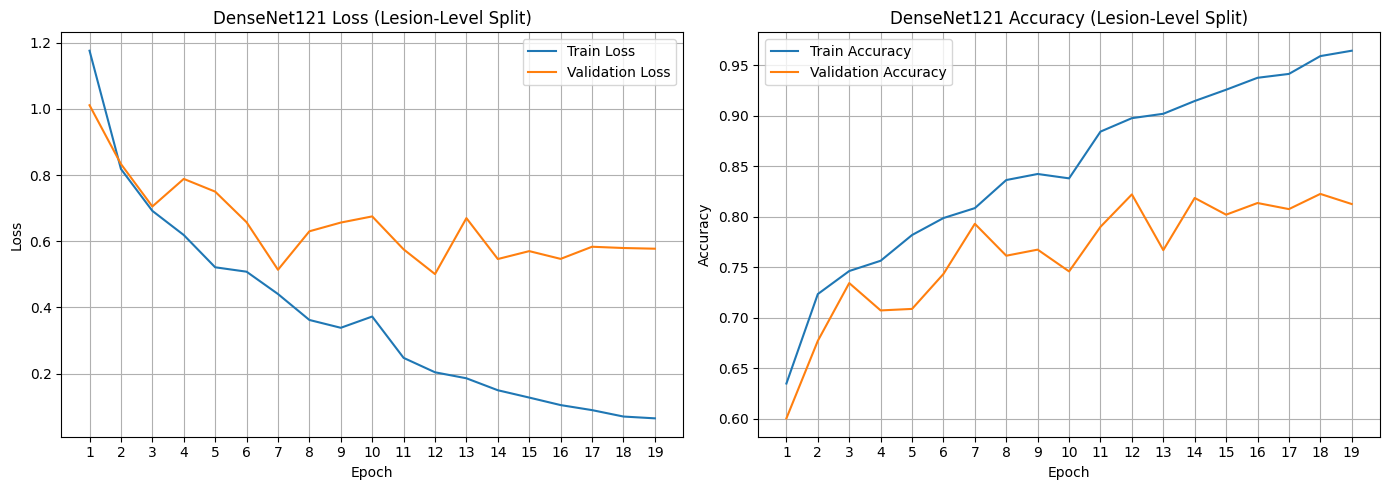

Curves saved to: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\figures\densenet121_training\lesion_training_curves.png


In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the saved lesion-level training history
history_path = FIGURE_DIR / "lesion_training_history.csv"
history_df = pd.read_csv(history_path)

epochs = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(epochs, history_df["train_loss"], label="Train Loss")
axes[0].plot(epochs, history_df["val_loss"], label="Validation Loss")
axes[0].set_title("DenseNet121 Loss (Lesion-Level Split)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(list(epochs))
axes[0].legend()
axes[0].grid(True)

# Accuracy curve
axes[1].plot(epochs, history_df["train_accuracy"], label="Train Accuracy")
axes[1].plot(epochs, history_df["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("DenseNet121 Accuracy (Lesion-Level Split)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(list(epochs))
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lesion_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Curves saved to:", FIGURE_DIR / "lesion_training_curves.png")


FINAL TEST EVALUATION
Checkpoint: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\model\densenet121_ham10000_lesion_best.pt
Device: cuda

OVERALL PERFORMANCE
Test samples: 2014
Test Accuracy: 0.8118 (81.18%)
Test Macro F1: 0.6748

PER-CLASS CLASSIFICATION REPORT
              precision  recall  f1-score    support
akiec            0.5286  0.5441    0.5362    68.0000
bcc              0.6090  0.8100    0.6953   100.0000
bkl              0.6107  0.7268    0.6637   205.0000
df               0.6667  0.4545    0.5405    22.0000
mel              0.5391  0.5901    0.5634   222.0000
nv               0.9461  0.8760    0.9097  1363.0000
vasc             0.7021  0.9706    0.8148    34.0000
accuracy         0.8118  0.8118    0.8118     0.8118
macro avg        0.6575  0.7103    0.6748  2014.0000
weighted avg     0.8291  0.8118    0.8176  2014.0000


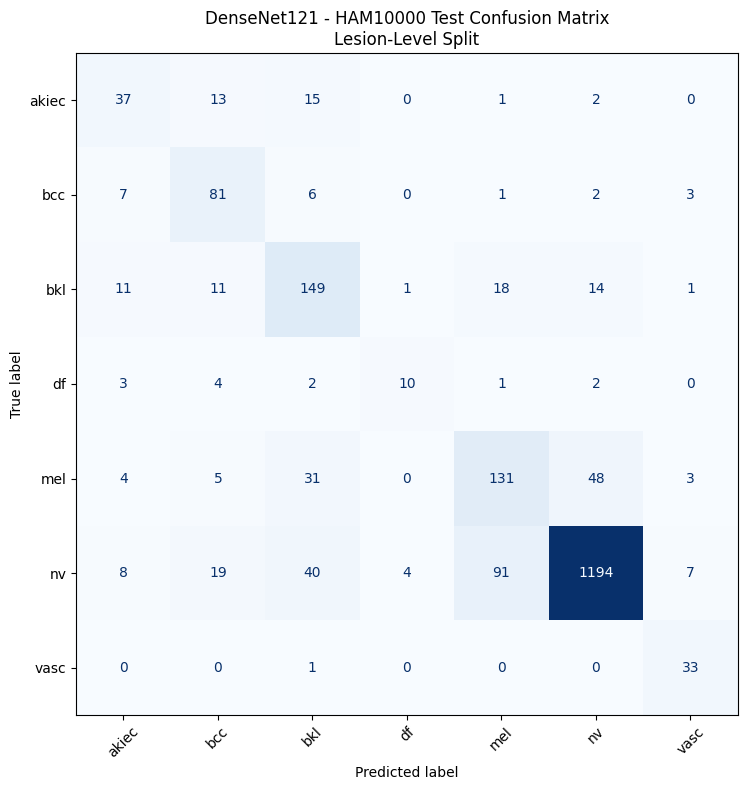

EVALUATION ARTIFACTS SAVED
Overall metrics: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\figures\densenet121_training\lesion_test_metrics.csv
Classification report: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\figures\densenet121_training\lesion_test_classification_report.csv
Confusion matrix: C:\Users\vansh\SOFTWARE-ENGINEERING\SOFTWARE-ENGINEERING\figures\densenet121_training\lesion_test_confusion_matrix.png

Final test evaluation completed.


In [19]:

# Cell 8: Final Evaluation on the Lesion-Level Test Set

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Verify and load the best lesion-level checkpoint

BEST_MODEL_PATH = MODEL_DIR / "densenet121_ham10000_lesion_best.pt"

assert BEST_MODEL_PATH.exists(), (
    f"Best lesion-level model not found: {BEST_MODEL_PATH}"
)

print("FINAL TEST EVALUATION")
print(f"Checkpoint: {BEST_MODEL_PATH}")
print(f"Device: {DEVICE}")

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.eval()

# 2. Generate predictions on the test set

test_predictions = []
test_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)

        logits = model(images)
        predictions = torch.argmax(logits, dim=1)

        test_predictions.extend(predictions.cpu().tolist())
        test_targets.extend(labels.cpu().tolist())

# 3. Calculate evaluation metrics

test_accuracy = accuracy_score(
    test_targets,
    test_predictions
)

test_macro_f1 = f1_score(
    test_targets,
    test_predictions,
    labels=all_class_indices,
    average="macro",
    zero_division=0
)

print("\nOVERALL PERFORMANCE")
print(f"Test samples: {len(test_targets)}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Test Macro F1: {test_macro_f1:.4f}")

# 4. Per-class classification report

report_dict = classification_report(
    test_targets,
    test_predictions,
    labels=all_class_indices,
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=4,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()

print("\nPER-CLASS CLASSIFICATION REPORT")
print(report_df.round(4).to_string())

# Save report
report_path = FIGURE_DIR / "lesion_test_classification_report.csv"
report_df.to_csv(report_path, index=True)

# 5. Confusion matrix

cm = confusion_matrix(
    test_targets,
    test_predictions,
    labels=all_class_indices
)

fig, ax = plt.subplots(figsize=(10, 8))

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

display_plot.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "DenseNet121 - HAM10000 Test Confusion Matrix\n"
    "Lesion-Level Split"
)

plt.tight_layout()

confusion_path = FIGURE_DIR / "lesion_test_confusion_matrix.png"

plt.savefig(
    confusion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# 6. Save overall metrics

metrics_df = pd.DataFrame([{
    "model": "DenseNet121",
    "evaluation": "Lesion-level test set",
    "checkpoint": BEST_MODEL_PATH.name,
    "test_samples": len(test_targets),
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1
}])

metrics_path = FIGURE_DIR / "lesion_test_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("EVALUATION ARTIFACTS SAVED")
print(f"Overall metrics: {metrics_path}")
print(f"Classification report: {report_path}")
print(f"Confusion matrix: {confusion_path}")
print("\nFinal test evaluation completed.")
